# Problem 1: 

## (a) 
We pick six sample $x$-values (they do not need to be in order) and compute $y = x^2$ for each.

**Chosen dataset:**

| $x$ | $y = x^2$ |
|:---:|:---------:|
| $-2$ | $4$ |
| $0$ | $0$ |
| $1$ | $1$ |
| $4$ | $16$ |
| $6$ | $36$ |
| $8$ | $64$ |

We form the $6 \times 2$ data matrix $X$ from these $(x, y)$ pairs,
center the data $\tilde X = X - \bar x$, and compute
$\tilde X = U\Sigma V^\top$ (SVD).
The first column of $V$ ($v_1$) is the first principal component,
so the best-fit line passes through $\bar x$ in the direction of $v_1$.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

x = np.array([-2, 0, 1, 4, 6, 8], dtype=float)
y = x**2
X = np.column_stack([x, y])
print("Dataset (x, y):\n", X)

Dataset (x, y):
 [[-2.  4.]
 [ 0.  0.]
 [ 1.  1.]
 [ 4. 16.]
 [ 6. 36.]
 [ 8. 64.]]


In [16]:
x_bar = X.mean(axis=0)
X_tilde = X - x_bar                      # center the data
U, S, Vt = np.linalg.svd(X_tilde, full_matrices=False)
v1 = Vt[0]                               # first right singular vector = PC1

print("Mean:", x_bar)
print("U =\n", U)
print("Singular values:", S)
print("V^T =\n", Vt)
print("PC1 direction v1:", v1)

Mean: [ 2.8333 20.1667]
U =
 [[-0.2909  0.7466]
 [-0.3553  0.0166]
 [-0.3356 -0.2302]
 [-0.0692 -0.498 ]
 [ 0.2812 -0.2827]
 [ 0.7698  0.2478]]
Singular values: [57.3209  3.4613]
V^T =
 [[ 0.1363  0.9907]
 [-0.9907  0.1363]]
PC1 direction v1: [0.1363 0.9907]


SVD line: y = 7.2662 x + -0.4208


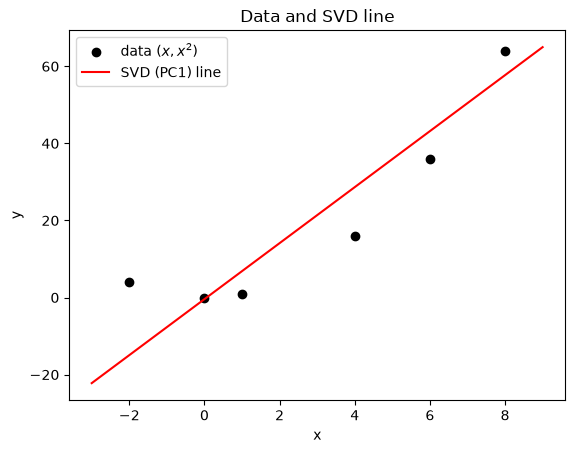

In [13]:
slope = v1[1] / v1[0]
intercept = x_bar[1] - slope * x_bar[0]
print(f"SVD line: y = {slope:.4f} x + {intercept:.4f}")

xs = np.linspace(-3, 9, 100)
plt.scatter(x, y, color="k", label="data $(x, x^2)$")
plt.plot(xs, slope*xs + intercept, "r", label="SVD (PC1) line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.title("Data and SVD line")
plt.show()

## (b)
Different set of six x-values ($x = \{5, 6, 7, 8, 9, 10\}$).

x = {-2,0,1,4,6,8} : slope=7.2662, intercept=-0.4208
x = {5,6,7,8,9,10} : slope=15.1416, intercept=-54.3953


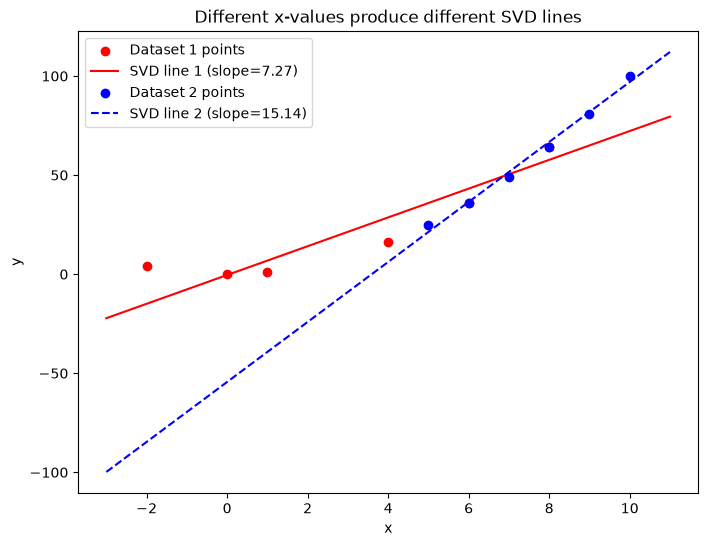

In [17]:
def svd_line(x):
    X = np.column_stack([x, x**2])
    m = X.mean(axis=0)
    v1 = np.linalg.svd(X - m)[2][0]
    s = v1[1] / v1[0]
    return s, m[1] - s*m[0]

# Dataset 1: from part (a)
x1 = np.array([-2, 0, 1, 4, 6, 8], dtype=float)
s1, i1 = svd_line(x1)
print("x = {-2,0,1,4,6,8} : slope=%.4f, intercept=%.4f" % (s1, i1))

# Dataset 2: different x-values
x2 = np.arange(5.0, 11.0)
s2, i2 = svd_line(x2)
print("x = {5,6,7,8,9,10} : slope=%.4f, intercept=%.4f" % (s2, i2))

# Plot both datasets and their SVD lines
t = np.linspace(-3, 11, 200)
plt.figure(figsize=(8, 6))
plt.scatter(x1, x1**2, color='red', zorder=5, label='Dataset 1 points')
plt.plot(t, s1*t + i1, 'r-', label=f'SVD line 1 (slope={s1:.2f})')
plt.scatter(x2, x2**2, color='blue', zorder=5, label='Dataset 2 points')
plt.plot(t, s2*t + i2, 'b--', label=f'SVD line 2 (slope={s2:.2f})')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Different x-values produce different SVD lines')
plt.legend()
plt.show()

**Yes, the line changes.** The SVD line depends only on the sample points: it passes through their mean and points along their direction of maximum variance. Since $y = x^2$ is not linear, different x-values sample a different part of the curve, which has a different mean and spread. The point cloud changes, so its principal component changes too.

## (c) 

Regression line: y = 6.0709 x + 2.9657
SVD line:        y = 7.2662 x + -0.4208


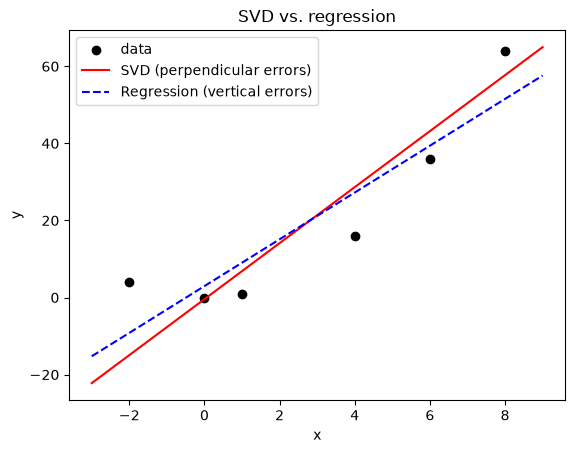

In [15]:
b1, b0 = np.polyfit(x, y, 1)
print(f"Regression line: y = {b1:.4f} x + {b0:.4f}")
print(f"SVD line:        y = {slope:.4f} x + {intercept:.4f}")

plt.scatter(x, y, color="k", label="data")
plt.plot(xs, slope*xs + intercept, "r", label="SVD (perpendicular errors)")
plt.plot(xs, b1*xs + b0, "b--", label="Regression (vertical errors)")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.title("SVD vs. regression")
plt.show()

Looking at SVD-based linear approximation with the result of fitting a linear regression line of y on x **They are not the same.** Both lines pass through the mean, but  The SVD line minimizes the sum of squared **perpendicular** distances to the line, treating $x$ and $y$ symmetrically. Meanwhile, Linear regression minimizes squared **vertical** errors in $y$ only. Since the data do not lie exactly on a line, the two criteria give different slopes.